# Cointegration and Vector Error-Correction Models

Notebook 07 distinguished stochastic trends from stationary fluctuations. Notebook 08 used differencing to model changes, and Notebook 12 extended autoregressive dynamics to several variables. I now ask whether individually nonstationary series can share a stationary relationship.

Cointegration concerns a long-run combination of levels, while an error-correction model combines deviations from that relationship with short-run dynamics. I contrast unrelated random walks and a shared-trend construction, then estimate and test the relationship, fit a vector error-correction model (VECM), inspect residuals and forecast a reserved continuation.

All examples are simulations. Their population relationships are known by construction, but estimated coefficients and test results still vary across finite histories. No market pair is assumed to be cointegrated, and no investment strategy follows automatically from a stationary relationship.

In [1]:
from pathlib import Path
import sys
repository = Path.cwd()
if not (repository / "src" / "finstats").is_dir():
    repository = repository.parent
if not (repository / "src" / "finstats").is_dir():
    raise RuntimeError("Run from the repository root or notebooks directory")
sys.path.insert(0, str(repository / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from statsmodels.tsa.api import VAR
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "font.size": 11, "axes.titlesize": 12,
    "legend.frameon": False, "lines.linewidth": 1.8,
})
from statsmodels.tsa.vector_ar.util import comp_matrix

from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, select_coint_rank
from statsmodels.tsa.vector_ar.var_model import ma_rep


## 1. Nonstationary Levels and Spurious Regression

### Integration

**Definition: integration of order one.** A series is $I(1)$ when its level has a unit-root stochastic trend and its first difference is $I(0)$, a stationary short-memory process in the framework used here. More generally, $I(d)$ requires $d$ differences to obtain $I(0)$. A deterministic trend and a unit-root stochastic trend are different mechanisms, as in Notebook 07.

For a random walk, $Y_t=Y_{t-1}+u_t$, the difference is the stationary innovation $u_t$. A finite level history can nevertheless display a high sample correlation with another random walk.

### Spurious Regression

Regressing one unrelated $I(1)$ level on another can give a large fitted $R^2$ and apparently significant conventional coefficient tests. The residual may retain a stochastic trend. Ordinary stationary-regression t references then do not provide valid evidence of a relationship. A visually close fit or high correlation does not establish cointegration.

I use 1000 level observations and seed 13013. The first 800 levels are used for estimation, and the final 200 are reserved before any test or fit. Figures before forecasting use only training observations.

## 2. Cointegration

### Definition

**Definition: cointegration.** For a vector of $I(1)$ series $\mathbf Y_t$, a nonzero vector $\boldsymbol\beta$ defines a cointegrating relationship if
$$s_t=\boldsymbol\beta^\top\mathbf Y_t$$
is $I(0)$. The individual series have stochastic trends, while this combination removes them. Deterministic intercepts or trends can be included when justified; the worked population has neither.

For two variables, normalize the first coefficient to one:
$$s_t=Y_{1,t}-bY_{2,t},\qquad\boldsymbol\beta=(1,-b)^\top.$$
Multiplying the entire vector by a nonzero constant gives the same stationary relation. This normalization identifies its scale; it is not a numerical bound on the estimated slope.

Cointegration differs from correlation. Correlation describes association in values; cointegration concerns the integration order of a level combination. Differencing both series may remove a common trend but omit information about deviations from a long-run relationship.

### Illustration: A Shared Trend and a Stationary Spread

Construct a random walk $W_t$ and an independent stationary AR(1) spread:
$$W_t=W_{t-1}+\eta_t,\qquad s_t=\rho s_{t-1}+\xi_t,\qquad |\rho|<1.$$
Set
$$Y_{2,t}=W_t,\qquad Y_{1,t}=bW_t+s_t.$$
Both levels are $I(1)$, but $Y_{1,t}-bY_{2,t}=s_t$ is stationary. I use $b=1.4$, $\rho=.7$, Gaussian innovation SDs one for $\eta_t$ and $.65$ for $\xi_t$. The spread begins from its stationary Gaussian law; the common trend begins at zero. The trend's level variance grows, while spread variance is $.65^2/(1-.7^2)$.

The unrelated comparison replaces $Y_1$ with an independent random walk, retaining the same $Y_2$. For each training pair I fit a descriptive level regression with an intercept and plot its residual. This differs from a known population spread because its slope and intercept are estimated.

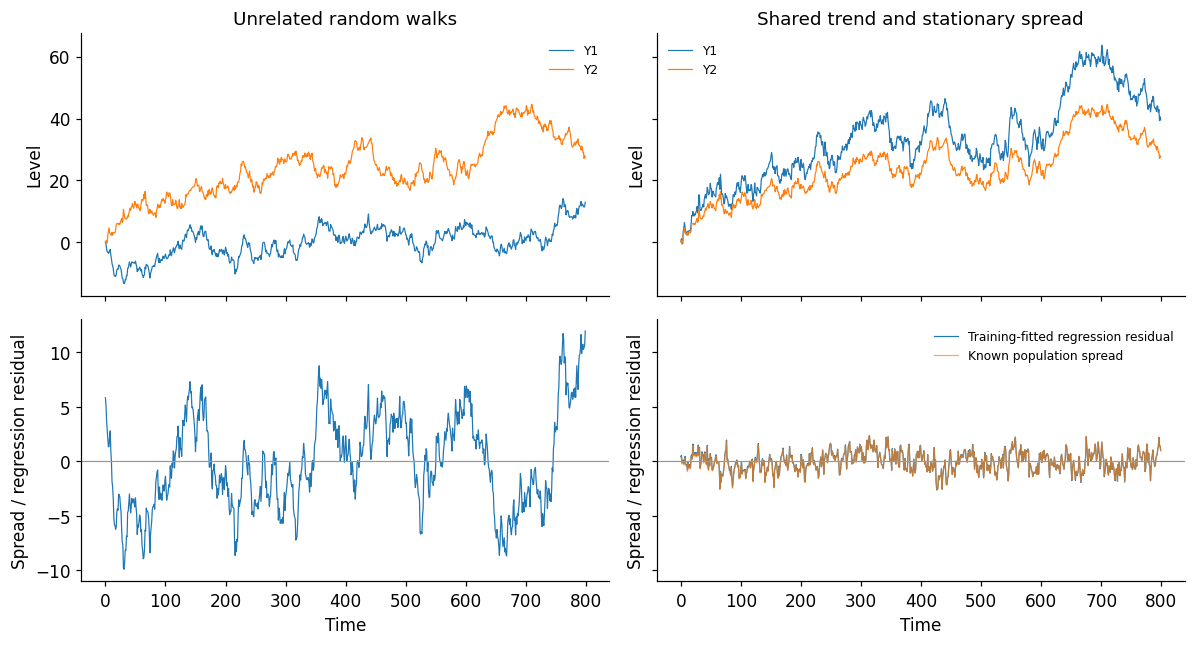

,Fitted slope,Level-regression R²,Sample level correlation
Construction,,,
Unrelated random walks,0.2470,0.2267,0.4761
Shared trend and stationary spread,1.4044,0.9957,0.9978


Known spread population variance: 0.8284313725490197


In [2]:
sample_size, training_size, horizon = 1000, 800, 24
b_true, rho_true, spread_sd = 1.4, .7, .65
rng = np.random.default_rng(13013)
common_shocks = rng.normal(size=sample_size-1)
independent_shocks = rng.normal(size=sample_size-1)
spread_shocks = rng.normal(scale=spread_sd, size=sample_size-1)
common_trend = np.r_[0., np.cumsum(common_shocks)]
independent_walk = np.r_[0., np.cumsum(independent_shocks)]
spread = np.empty(sample_size)
spread[0] = rng.normal(scale=spread_sd / np.sqrt(1-rho_true**2))
for t in range(1,sample_size):
    spread[t] = rho_true * spread[t-1] + spread_shocks[t-1]
index = np.arange(sample_size)
cointegrated = pd.DataFrame({"Y1":b_true*common_trend+spread,"Y2":common_trend},index=index)
unrelated = pd.DataFrame({"Y1":independent_walk,"Y2":common_trend},index=index)
train, reserved = cointegrated.iloc[:training_size], cointegrated.iloc[training_size:]
examples = {"Unrelated random walks":unrelated.iloc[:training_size],
            "Shared trend and stationary spread":train}
regression_rows = []
fig, axes = plt.subplots(2,2,figsize=(11,6),sharex=True,sharey="row")
for column,(name,values) in enumerate(examples.items()):
    X = np.column_stack([np.ones(len(values)),values.Y2])
    coefficient = np.linalg.lstsq(X,values.Y1,rcond=None)[0]
    residual = values.Y1.to_numpy()-X@coefficient
    r_squared = 1-np.sum(residual**2)/np.sum((values.Y1-values.Y1.mean())**2)
    regression_rows.append({"Construction":name,"Fitted slope":coefficient[1],
                            "Level-regression R²":r_squared,"Sample level correlation":values.corr().iloc[0,1]})
    axes[0,column].plot(values.index,values.Y1,lw=.8,label="Y1")
    axes[0,column].plot(values.index,values.Y2,lw=.8,label="Y2")
    axes[0,column].set(title=name,ylabel="Level")
    axes[1,column].plot(values.index,residual,lw=.8,label="Training-fitted regression residual")
    if column==1:
        axes[1,column].plot(values.index,spread[:training_size],lw=.8,alpha=.7,color="C1",label="Known population spread")
    axes[1,column].axhline(0,color="0.6",lw=.8)
    axes[1,column].set(xlabel="Time",ylabel="Spread / regression residual")
axes[0,0].legend(fontsize=8);axes[0,1].legend(fontsize=8)
axes[1,1].legend(fontsize=8)
fig.tight_layout();plt.show()
display(pd.DataFrame(regression_rows).set_index("Construction").round(4))
print("Known spread population variance:",spread_sd**2/(1-rho_true**2))
np.testing.assert_allclose(cointegrated.Y1-b_true*cointegrated.Y2,spread,atol=1e-12)


The shared-trend construction is cointegrated because its combination is stationary by design, not because the level regression has a high $R^2$. The unrelated pair has no population cointegration even if its finite paths appear related. A regression residual alone does not reveal its population integration order.

## 3. Integration and Cointegration Tests

### Unit-Root Checks

The ADF test from Notebook 07 assesses a unit-root null for each level and first difference. I use an intercept and BIC lag selection, with training observations only. Failure to reject a level unit root and rejection for differences are consistent with $I(1)$, but do not prove it. Test power, deterministic terms and finite-sample errors matter. With market data, integration order must be investigated before adopting the $I(1)$ framework.

In [3]:
from inspect import signature
# Preserve tuple results across supported statsmodels versions.
adf_options = {"result_object": False} if "result_object" in signature(adfuller).parameters else {}
adf_rows = []
for name,values in examples.items():
    for variable in values:
        for transformation,series in [("Level",values[variable]),("First difference",values[variable].diff().dropna())]:
            result = adfuller(series,regression="c",autolag="BIC",**adf_options)
            adf_rows.append({"Construction":name,"Variable":variable,"Series":transformation,
                             "ADF statistic":result[0],"p-value":result[1],"Selected lag":result[2]})
display(pd.DataFrame(adf_rows).set_index(["Construction","Variable","Series"]).round(4))


ADF statistic  \
Construction                       Variable Series                            
Unrelated random walks             Y1       Level                   -2.2277   
                                            First difference       -27.1370   
                                   Y2       Level                   -2.5075   
                                            First difference       -28.6493   
Shared trend and stationary spread Y1       Level                   -2.4417   
                                            First difference       -31.1924   
                                   Y2       Level                   -2.5075   
                                            First difference       -28.6493   

                                                              p-value  \
Construction                       Variable Series                      
Unrelated random walks             Y1       Level              0.1963   
                                            First difference   0.0000   
                                   Y2       Level              0.1137   
                                            First difference   0.0000   
Shared trend and stationary spread Y1       Level              0.1303   
                                            First difference   0.0000   
                                   Y2       Level              0.1137   
                                            First difference   0.0000   

                                                              Selected lag  
Construction                       Variable Series                          
Unrelated random walks             Y1       Level                        0  
                                            First difference             0  
                                   Y2       Level                        0  
                                            First difference             0  
Shared trend and stationary spread Y1       Level                        1  
                                            First difference             0  
                                   Y2       Level                        0  
                                            First difference             0

### Residual-Based Cointegration Test

The Engle–Granger procedure first estimates a level relationship,
$$Y_{1,t}=a+bY_{2,t}+e_t,$$
then checks whether its residual retains a unit root. The null is **no cointegration**, against a stationary-residual alternative under the $I(1)$ framework. Estimating $a$ and $b$ changes the reference distribution: an ordinary ADF p-value on the estimated residual is not the correct cointegration p-value.

I use the implementation's residual-based cointegration calibration, allowing an intercept and choosing auxiliary lags by BIC. The slope is not a causal effect. Finite-sample results may depend on the dependent-variable normalization. The zero-intercept population is compatible with estimating an intercept here; the system example below prespecifies no deterministic terms.

In [4]:
cointegration_rows = []
for name,values in examples.items():
    statistic,p_value,critical_values = coint(values.Y1,values.Y2,trend="c",autolag="bic")
    cointegration_rows.append({"Construction":name,"Cointegration statistic":statistic,
                               "p-value (no cointegration null)":p_value,"5% critical value":critical_values[1]})
display(pd.DataFrame(cointegration_rows).set_index("Construction").round(5))


,Cointegration statistic,p-value (no cointegration null),5% critical value
Construction,,,
Unrelated random walks,-2.86109,0.14702,-3.34379
Shared trend and stationary spread,-12.02592,0.00000,-3.34379


### System Cointegration and Rank

A system of $K$ series can have several independent stationary combinations. **Definition: cointegration rank.** The rank $r$ counts independent cointegrating relationships. Under the $I(1)$ framework, $K-r$ common stochastic trends remain.

The Johansen trace test compares $H_0:\operatorname{rank}(\Pi)\le r$ with a larger rank, using nonstandard reference values. Sequential rank selection is conditional on specification and subject to sampling error.

Deterministic terms and lag order affect the result. I prespecify no intercept or trend because the simulated system has neither. BIC chooses lagged differences from zero through five using training observations only. The corresponding levels VAR order is one larger. The package uses per-observation VAR criteria, as discussed in Notebook 12, with common target observations across orders. Johansen's no-deterministic-term setting matches the VECM specification here.

In [5]:
lag_selection = select_order(train,maxlags=5,deterministic="n")
k_ar_diff = int(lag_selection.selected_orders["bic"])
lag_table = pd.DataFrame({"Lagged differences":np.arange(6),
                          "AIC (package convention)":lag_selection.ics["aic"],
                          "BIC (package convention)":lag_selection.ics["bic"]}).set_index("Lagged differences")
display(lag_table.round(4))
print("BIC-selected lagged differences:",k_ar_diff,"; corresponding levels VAR order:",k_ar_diff+1)
rank_result = select_coint_rank(train,det_order=-1,k_ar_diff=k_ar_diff,method="trace",signif=.05)
display(pd.DataFrame({"Null rank at most":np.arange(len(rank_result.test_stats)),
                      "Trace statistic":rank_result.test_stats,
                      "5% critical value":rank_result.crit_vals}).set_index("Null rank at most").round(4))
selected_rank = int(rank_result.rank)
print("Selected rank:",selected_rank,"; known population rank: 1")
print("Rank selection is evidence under the stated model, not proof of the population rank.")


,AIC (package convention),BIC (package convention)
Lagged differences,,
0,-0.9051,-0.8698
1,-0.9060,-0.8471
2,-0.8982,-0.8158
3,-0.8947,-0.7886
4,-0.9019,-0.7723
5,-0.8961,-0.7429


BIC-selected lagged differences: 0 ; corresponding levels VAR order: 1


,Trace statistic,5% critical value
Null rank at most,,
0,134.9490,12.3212
1,1.1533,4.1296


Selected rank: 1 ; known population rank: 1
Rank selection is evidence under the stated model, not proof of the population rank.


## 4. Vector Error-Correction Models

### From a Levels VAR to Error Correction

A levels VAR(p) can be rewritten as
$$\Delta\mathbf Y_t=\Pi\mathbf Y_{t-1}
+\sum_{j=1}^{p-1}\Gamma_j\Delta\mathbf Y_{t-j}+\mathbf u_t,$$
where
$$\Pi=\sum_{j=1}^p A_j-I_K,\qquad
\Gamma_j=-\sum_{k=j+1}^p A_k.$$
A differenced VAR that discards the level term omits long-run adjustment when $\Pi\ne0$.

**Definition: VECM.** When $\Pi$ has reduced rank $r$, factor it as
$$\Pi=\alpha\beta^\top,$$
where $\beta$ contains the cointegrating vectors and $\alpha$ their adjustment coefficients. The term $\alpha\beta^\top\mathbf Y_{t-1}$ links previous level deviations with current changes. Here $\alpha$ denotes adjustment, not a tail probability or GARCH coefficient.

Rank zero removes error correction. Rank $K$ corresponds to stationary levels in this unit-root classification, rather than $K$ individually $I(1)$ series. Intermediate rank leaves common stochastic trends and stationary combinations. Rank is an explicit model specification assessed above, not a hidden coefficient cap.

### Bivariate Adjustment

With $s_{t-1}=Y_{1,t-1}-bY_{2,t-1}$ and no lagged differences,
$$\begin{aligned}
\Delta Y_{1,t}&=\alpha_1s_{t-1}+u_{1,t},\\
\Delta Y_{2,t}&=\alpha_2s_{t-1}+u_{2,t}.
\end{aligned}$$
Under this normalization, $\alpha_1<0$ moves $Y_1$ downward when it lies above the relationship. Both equations determine spread reversion:
$$s_t=(1+\alpha_1-b\alpha_2)s_{t-1}+u_{1,t}-bu_{2,t}.$$
Stationary spread dynamics require $|1+\alpha_1-b\alpha_2|<1$ in this simple model. The sign of one adjustment coefficient alone is insufficient.

For the simulated construction,
$$\beta=(1,-1.4)^\top,\qquad\alpha=(-.3,0)^\top.$$
Only $Y_1$ adjusts, and spread persistence is $.7$. A zero adjustment coefficient for $Y_2$ does not mean its shocks cannot affect the other variable. In larger models, lagged differences also affect adjustment.

### Estimation and Interpretation

I estimate a VECM by the established reduced-rank likelihood implementation, using the training-selected lag count and rank, without deterministic terms. No stability projection or arbitrary coefficient box is added. Rank specifies the model and normalization identifies its cointegrating vectors.

For rank one, compare the estimated relationship and adjustment with their known population values. The first beta coefficient is fixed to one for normalization, not estimated with zero uncertainty. Reported standard errors and p-values are nominal and conditional on the selected rank, lag structure and likelihood assumptions. They do not account for specification selection.

In [6]:
vecm_fit = VECM(train,k_ar_diff=k_ar_diff,coint_rank=selected_rank,deterministic="n").fit()
Pi_estimate = vecm_fit.alpha @ vecm_fit.beta.T
A_levels = vecm_fit.var_rep
np.testing.assert_allclose(Pi_estimate,A_levels.sum(axis=0)-np.eye(2),atol=1e-12)
if selected_rank == 1:
    beta_hat = vecm_fit.beta[:,0]
    alpha_hat = vecm_fit.alpha[:,0]
    display(pd.DataFrame({"Population beta":[1.,-b_true],"Estimated beta":beta_hat,
                          "Role":["Fixed normalization","Estimated relationship coefficient"]},index=train.columns))
    display(pd.DataFrame({"Population adjustment":[rho_true-1,0.],"Estimate":alpha_hat,
                          "Standard error":vecm_fit.stderr_alpha[:,0],"Nominal p-value":vecm_fit.pvalues_alpha[:,0]},
                         index=train.columns).round(5))
    if k_ar_diff == 0:
        print("Estimated spread autoregressive coefficient:",1+beta_hat@alpha_hat)
else:
    print("The selected rank differs from the known rank-one population; a single-spread interpretation is not used.")
    print("Estimated alpha:",vecm_fit.alpha)
    print("Estimated beta:",vecm_fit.beta)
print("Levels companion eigenvalue moduli:",np.abs(np.linalg.eigvals(comp_matrix(A_levels))))
print("Unit roots in the levels representation are expected for a cointegrated I(1) system.")


,Population beta,Estimated beta,Role
Y1,1.0,1.000000,Fixed normalization
Y2,-1.4,-1.399552,Estimated relationship coefficient


,Population adjustment,Estimate,Standard error,Nominal p-value
Y1,-0.3,-0.34025,0.06242,0.00000
Y2,0.0,-0.02405,0.03994,0.54706


Estimated spread autoregressive coefficient: 0.6934027513734119
Levels companion eigenvalue moduli: [0.69340275 1.        ]
Unit roots in the levels representation are expected for a cointegrated I(1) system.


### Residual Diagnostics

Residuals should have little serial dependence within or across equations if the dynamics are adequate. I report the adjusted lag-20 multivariate portmanteau test and a normality check, then show the four residual lag-correlation panels.

Residuals may remain correlated at the same date; the model estimates their covariance. That differs from unwanted serial dependence. Non-rejection does not establish a true long-run relationship or validate every likelihood assumption. Changing volatility and structural breaks would require additional assessment in a market application.

,Statistic,p-value
Check,,
"VECM residual portmanteau, lag 20",99.3065,0.0522
VECM residual multivariate normality,2.5411,0.6373


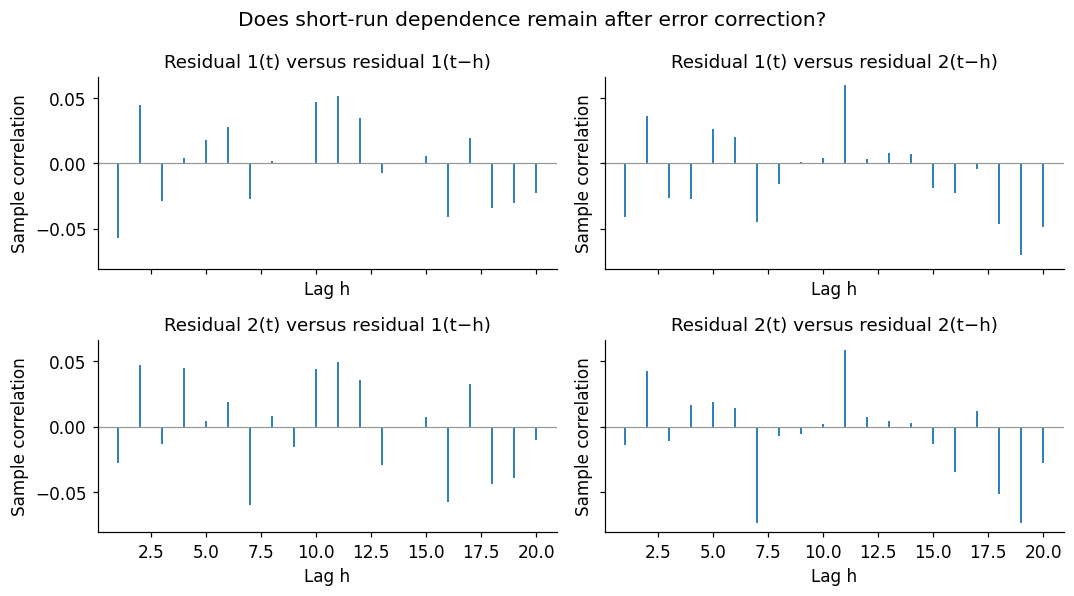

In [7]:
whiteness = vecm_fit.test_whiteness(nlags=20,adjusted=True)
normality = vecm_fit.test_normality()
display(pd.DataFrame([
    {"Check":"VECM residual portmanteau, lag 20","Statistic":whiteness.test_statistic,"p-value":whiteness.pvalue},
    {"Check":"VECM residual multivariate normality","Statistic":normality.test_statistic,"p-value":normality.pvalue},
]).set_index("Check").round(4))
residuals = np.asarray(vecm_fit.resid)
fig,axes = plt.subplots(2,2,figsize=(10,5.5),sharex=True,sharey=True)
for i in range(2):
    for j in range(2):
        correlations = [np.corrcoef(residuals[h:,i],residuals[:-h,j])[0,1] for h in range(1,21)]
        axes[i,j].vlines(np.arange(1,21),0,correlations,color="C0",lw=1.2)
        axes[i,j].axhline(0,color="0.6",lw=.8)
        axes[i,j].set(title=f"Residual {i+1}(t) versus residual {j+1}(t−h)",xlabel="Lag h",ylabel="Sample correlation")
fig.suptitle("Does short-run dependence remain after error correction?")
fig.tight_layout();plt.show()


In this realization, the lag-20 residual portmanteau p-value is about .052. It narrowly exceeds .05, so residual adequacy should not be described as firmly established; the lag-correlation panels and the chosen test horizon remain relevant.

## 5. Forecasting Levels and the Long-Run Relationship

### Conditional Forecasts

Iterate the error-correction equation using training-cutoff information:
$$\widehat{\Delta\mathbf y}_{n+h|n}=\widehat\alpha\widehat\beta^\top
\widehat{\mathbf y}_{n+h-1|n}
+\sum_j\widehat\Gamma_j\widehat{\Delta\mathbf y}_{n+h-j|n},$$
then recover levels by adding each change to the previous level. Retain observed values before the origin and set future mean-zero innovations to zero.

Levels need not revert to a fixed unconditional mean. The common trend remains nonstationary; error correction governs a combination of levels. In the known population, expected spread is $\rho^hs_n$, while the future common-trend mean equals its current level:
$$E_n[Y_{2,n+h}]=W_n,\qquad
E_n[Y_{1,n+h}]=bW_n+\rho^hs_n.$$
These known-parameter forecasts are simulation references, not available empirical predictors.

### Forecast Uncertainty

The levels VAR representation supplies Notebook 12's innovation-propagation matrices:
$$\Omega_h=\sum_{j=0}^{h-1}\Phi_j\Sigma_u\Phi_j^\top.$$
This finite-horizon covariance is well defined even with level unit roots. Gaussian marginal prediction intervals substitute fitted parameters and omit estimation uncertainty. They are pointwise bands for individual observations, not confidence intervals for the equilibrium relation.

For a fixed rank-one fitted relationship, forecast spread variance is $\widehat\beta^\top\Omega_h\widehat\beta$. It can behave differently from the levels' growing uncertainty. The spread plot fixes beta at its training estimate rather than refitting after observing the continuation.

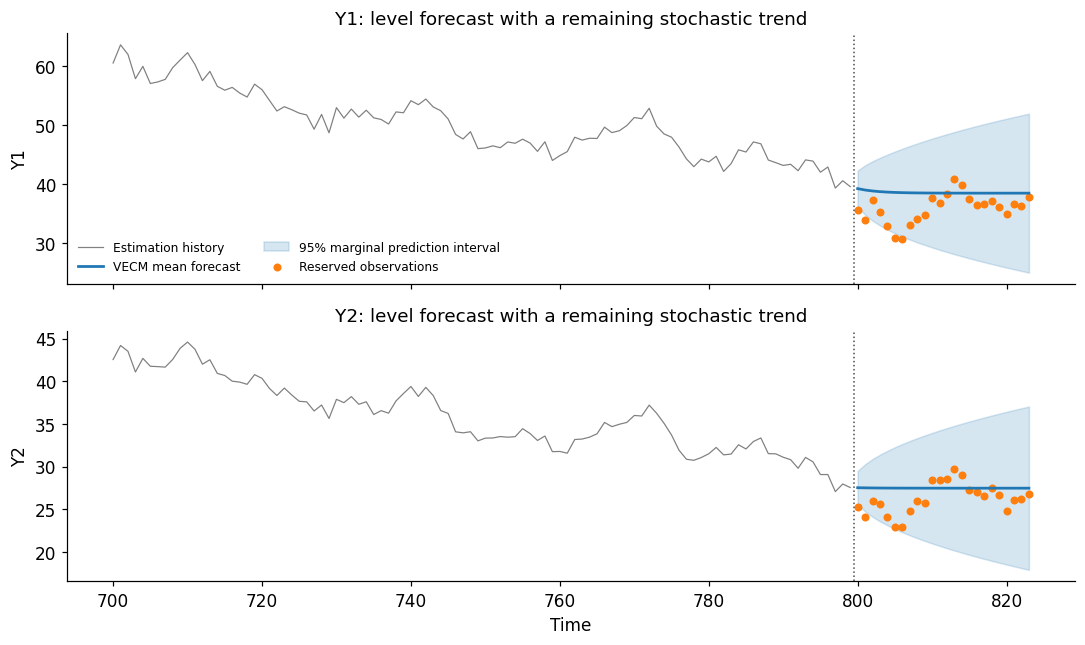

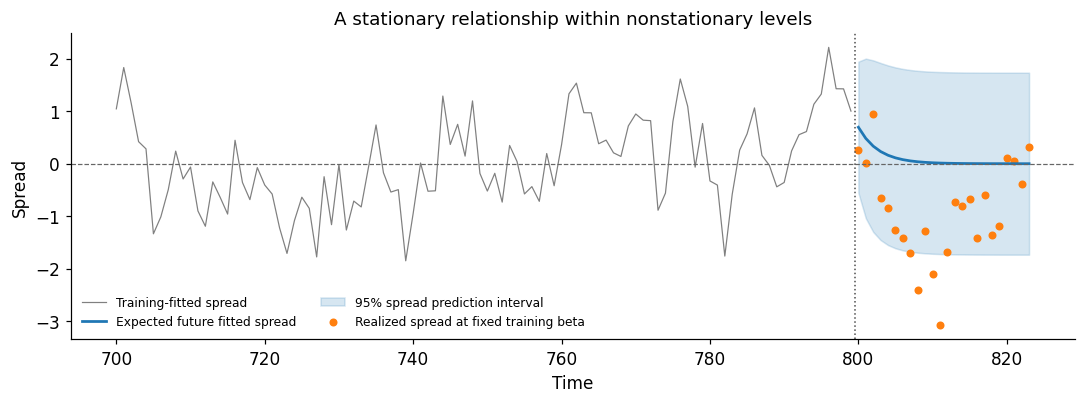

In [8]:
predicted,lower,upper = vecm_fit.predict(steps=horizon,alpha=.05)
actual = reserved.iloc[:horizon]
# Verify the forecast independently by iterating the error-correction equation.
level_history = list(train.to_numpy())
difference_history = list(np.diff(train.to_numpy(),axis=0))
explicit_predictions = []
for h in range(horizon):
    change = Pi_estimate @ level_history[-1]
    for j in range(k_ar_diff):
        change += vecm_fit.gamma[:,2*j:2*(j+1)] @ difference_history[-j-1]
    level = level_history[-1] + change
    explicit_predictions.append(level)
    level_history.append(level);difference_history.append(change)
np.testing.assert_allclose(predicted,explicit_predictions,atol=1e-9)
propagation = ma_rep(A_levels,maxn=horizon-1)
forecast_covariance = np.cumsum(np.array([phi@vecm_fit.sigma_u@phi.T for phi in propagation]),axis=0)
np.testing.assert_allclose(upper-predicted,stats.norm.ppf(.975)*np.sqrt(np.diagonal(forecast_covariance,axis1=1,axis2=2)),atol=1e-9)
fig,axes = plt.subplots(2,1,figsize=(10,6),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(train.index[-100:],train.iloc[-100:,j],color="0.5",lw=.8,label="Estimation history")
    ax.plot(actual.index,predicted[:,j],color="C0",label="VECM mean forecast")
    ax.fill_between(actual.index,lower[:,j],upper[:,j],color="C0",alpha=.18,label="95% marginal prediction interval")
    ax.scatter(actual.index,actual.iloc[:,j],color="C1",s=18,label="Reserved observations")
    ax.axvline(training_size-.5,color="0.3",ls=":",lw=1)
    ax.set(ylabel=train.columns[j],title=f"{train.columns[j]}: level forecast with a remaining stochastic trend")
axes[0].legend(fontsize=8,ncol=2);axes[-1].set_xlabel("Time")
fig.tight_layout();plt.show()
if selected_rank == 1:
    fitted_spread_history = train.to_numpy()@beta_hat
    predicted_spread = predicted@beta_hat
    observed_spread = actual.to_numpy()@beta_hat
    spread_variance = np.einsum("i,hij,j->h",beta_hat,forecast_covariance,beta_hat)
    assert (spread_variance>0).all()
    fig,ax = plt.subplots(figsize=(10,3.8))
    ax.plot(train.index[-100:],fitted_spread_history[-100:],color="0.5",lw=.8,label="Training-fitted spread")
    ax.plot(actual.index,predicted_spread,color="C0",label="Expected future fitted spread")
    ax.fill_between(actual.index,predicted_spread-stats.norm.ppf(.975)*np.sqrt(spread_variance),
                    predicted_spread+stats.norm.ppf(.975)*np.sqrt(spread_variance),color="C0",alpha=.18,label="95% spread prediction interval")
    ax.scatter(actual.index,observed_spread,color="C1",s=18,label="Realized spread at fixed training beta")
    ax.axhline(0,color="0.4",ls="--",lw=.8)
    ax.axvline(training_size-.5,color="0.3",ls=":",lw=1)
    ax.set(xlabel="Time",ylabel="Spread",title="A stationary relationship within nonstationary levels")
    ax.legend(fontsize=8,ncol=2)
    fig.tight_layout();plt.show()


### Forecast Evaluation and Benchmarks

Compare the VECM with an unrestricted levels VAR of the corresponding order, a VAR of differences that omits error correction, and a zero-drift random walk. The differences VAR uses the same count of lagged differences as the VECM. When that count is zero and there is no deterministic term, its forecast changes are zero and its levels equal the random-walk benchmark.

The unrestricted levels VAR estimates both equations without reduced rank. The VECM explicitly uses the training-selected rank. All fitted models use identical training targets and no deterministic terms; their maintained dynamics differ. No reserved observation enters estimation or specification selection. A known-parameter forecast illustrates the theoretical target.

Report ME, RMSE and MAE for each series over the first 24 reserved observations, using Notebook 08's error convention. These are level-forecast errors in simulation units, not evidence that one model is universally better or that a spread can be traded profitably.

In [9]:
levels_fit = VAR(train).fit(k_ar_diff+1,trend="n")
levels_prediction = levels_fit.forecast(train.to_numpy()[-(k_ar_diff+1):],horizon)
differences = train.diff().dropna()
difference_fit = VAR(differences.reset_index(drop=True)).fit(k_ar_diff,trend="n")
assert len(vecm_fit.resid) == levels_fit.nobs == difference_fit.nobs
if k_ar_diff:
    difference_prediction = difference_fit.forecast(differences.to_numpy()[-k_ar_diff:],horizon)
else:
    difference_prediction = np.zeros((horizon,2))
differenced_level_prediction = train.iloc[-1].to_numpy()+np.cumsum(difference_prediction,axis=0)
walk_prediction = np.tile(train.iloc[-1].to_numpy(),(horizon,1))
future_horizons = np.arange(1,horizon+1)
last_W = train.Y2.iloc[-1]
last_spread = train.Y1.iloc[-1]-b_true*last_W
population_prediction = np.column_stack([b_true*last_W+rho_true**future_horizons*last_spread,
                                         np.repeat(last_W,horizon)])
forecast_rows = []
for name,prediction in [("VECM",predicted),("Unrestricted levels VAR",levels_prediction),
                        ("VAR of differences",differenced_level_prediction),("Zero-drift random walk",walk_prediction),
                        ("Known population forecast",population_prediction)]:
    for j,variable in enumerate(train.columns):
        errors = actual.iloc[:,j].to_numpy()-prediction[:,j]
        forecast_rows.append({"Model":name,"Variable":variable,"ME":errors.mean(),
                              "RMSE":np.sqrt(np.mean(errors**2)),"MAE":np.mean(np.abs(errors))})
forecast_table = pd.DataFrame(forecast_rows).set_index(["Model","Variable"])
display(forecast_table.round(4))
print("Every reported error uses the same 24 reserved target observations.")
if k_ar_diff == 0:
    np.testing.assert_allclose(differenced_level_prediction,walk_prediction)
    print("Here the VAR of differences and zero-drift random walk give identical forecasts.")


ME    RMSE     MAE
Model                     Variable                        
VECM                      Y1       -2.6980  3.6700  3.0098
                          Y2       -1.2092  2.1526  1.7784
Unrestricted levels VAR   Y1       -2.6813  3.6610  2.9963
                          Y2       -1.1973  2.1483  1.7716
VAR of differences        Y1       -3.7044  4.4329  3.8319
                          Y2       -1.2804  2.1889  1.8171
Zero-drift random walk    Y1       -3.7044  4.4329  3.8319
                          Y2       -1.2804  2.1889  1.8171
Known population forecast Y1       -2.8117  3.7513  3.1031
                          Y2       -1.2804  2.1889  1.8171

Every reported error uses the same 24 reserved target observations.
Here the VAR of differences and zero-drift random walk give identical forecasts.


Error correction retains information about a stationary level combination while allowing individual levels to carry stochastic trends. Differencing alone and error correction therefore answer different modelling questions. A favourable test does not establish an economic mechanism, and a fitted relation is not automatically stable across future regimes.

A stationary spread does not guarantee a profitable investment strategy. Adjustment may be slow, the relationship may change and estimated deviations carry uncertainty. No trading rule or financial performance is inferred here.

The known simulation provides a controlled illustration of integration, rank and adjustment. An empirical application would need economically motivated variables, integration and specification checks, stable estimation windows, diagnostics and evaluation on observations excluded from fitting. As in Cases 05 and 11, predictive performance must be assessed separately from in-sample fit.